In [147]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import scipy

In [148]:
CSV_PATH = "/Users/levirogalla/Projects/lib/ball-and-beam-ece-484/logs/angle_oscillation_0_2rad.txt"

csv_schema = {
  "sample": pl.Int64,
  "time_us": pl.Int64,
  "theta_desired": pl.Float64,
  "motor_voltage": pl.Float64,
  "theta": pl.Float64,
  "ball_pos": pl.Float64,
}
df = pl.read_csv(CSV_PATH, schema=csv_schema, has_header=False).head(-1).slice(100)# drop last row
df_original = df
df

sample,time_us,theta_desired,motor_voltage,theta,ball_pos
i64,i64,f64,f64,f64,f64
49194,24598353,0.0,-0.09669,-0.00001,0.12375
49204,24603353,0.0,-0.10112,0.00071,0.123913
49214,24608352,0.0,-0.103,0.00143,0.123837
49224,24613353,0.0,-0.103,0.00107,0.123717
49234,24618352,0.0,-0.10015,0.00071,0.123804
…,…,…,…,…,…
114575,57290415,0.0,-0.09992,0.00143,0.043317
114585,57295425,0.0,-0.08914,-0.00145,0.043263
114595,57300494,0.0,-0.57633,0.00035,0.043328


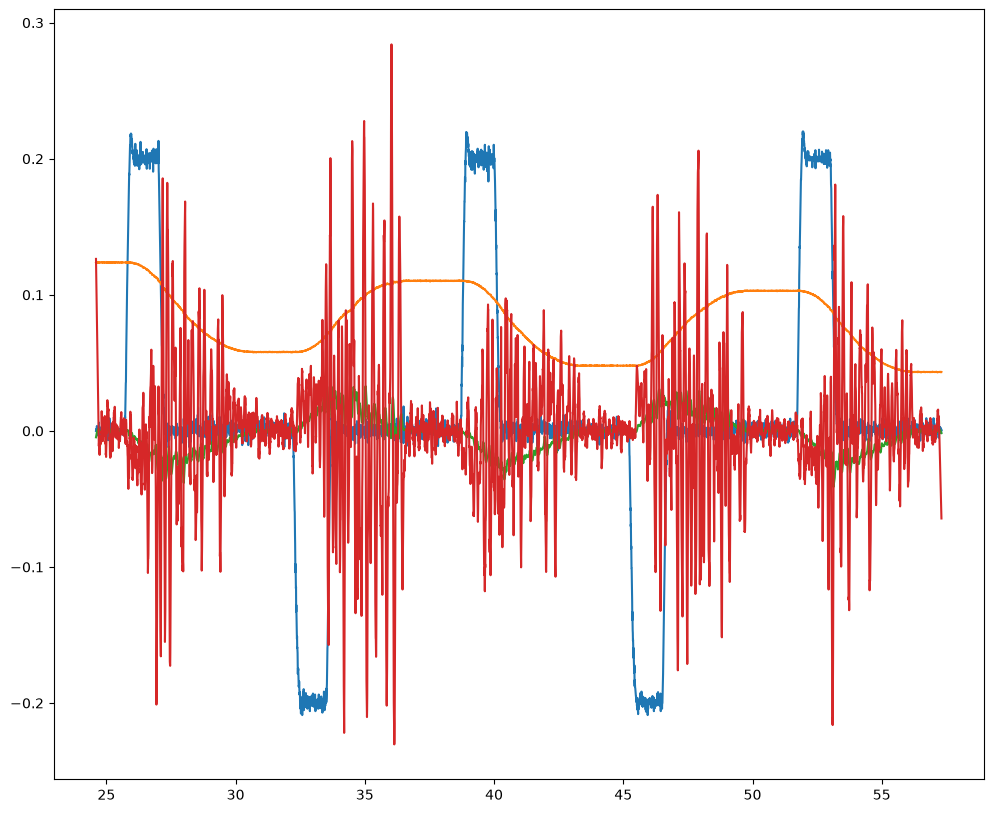

In [149]:
from scipy.signal import savgol_filter

dt = df_original["time_us"].diff().median() / 1e6

position = df_original["ball_pos"].to_numpy()

velocity = savgol_filter(position, window_length=40, polyorder=3, deriv=1, delta=dt)
acceleration = savgol_filter(position, window_length=40, polyorder=3, deriv=2, delta=dt)

df_original = df_original.with_columns([
    pl.Series("ball_velocity", velocity),
    pl.Series("ball_acceleration", acceleration),
])


plt.figure(figsize=(12, 10))
plt.plot(df_original["time_us"] / 1000000, df_original["theta"])
plt.plot(df_original["time_us"] / 1000000, df_original["ball_pos"])
plt.plot(df_original["time_us"] / 1000000, df_original["ball_velocity"])
plt.plot(df_original["time_us"] / 1000000, df_original["ball_acceleration"])
plt.show()

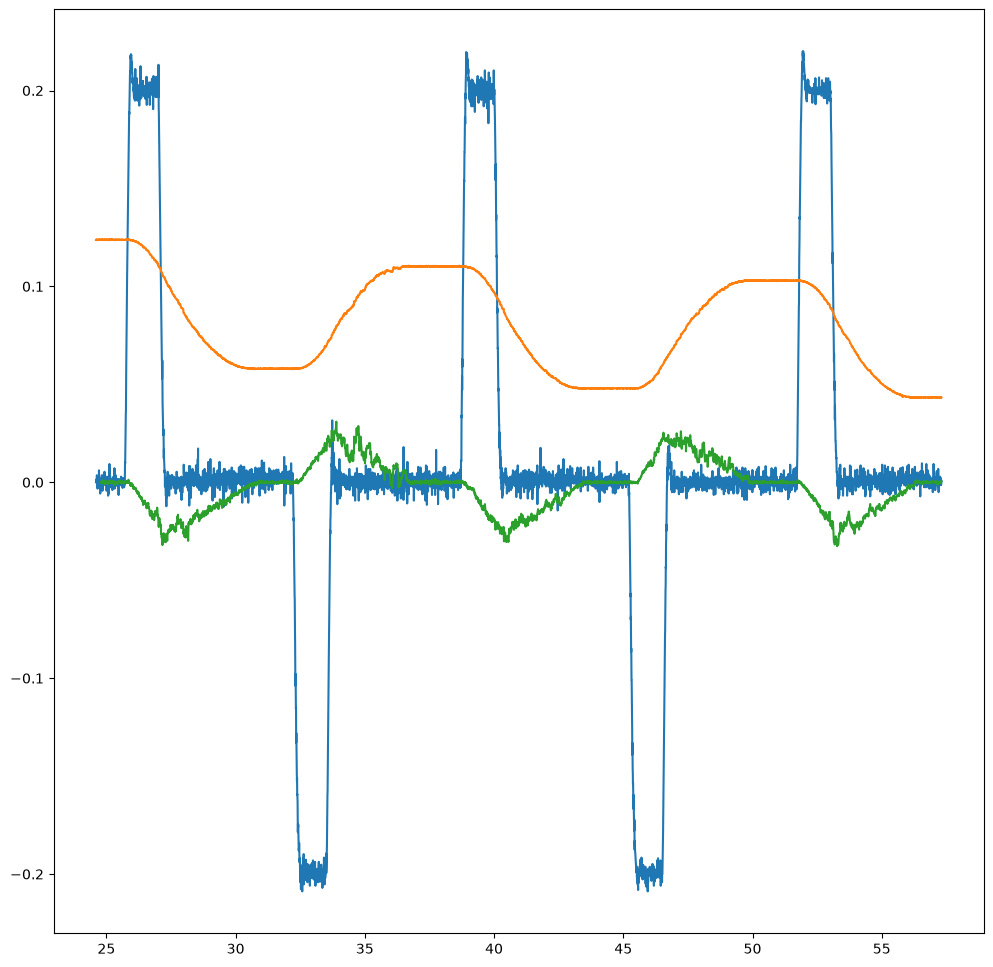

sample,time_us,theta_desired,motor_voltage,theta,ball_pos,ball_velocity
i64,i64,f64,f64,f64,f64,f64
49194,24598353,0.0,-0.09669,-0.00001,0.12375,null
49204,24603353,0.0,-0.10112,0.00071,0.123913,null
49214,24608352,0.0,-0.103,0.00143,0.123837,null
49224,24613353,0.0,-0.103,0.00107,0.123717,null
49234,24618352,0.0,-0.10015,0.00071,0.123804,null
…,…,…,…,…,…,…
114575,57290415,0.0,-0.09992,0.00143,0.043317,-0.000246
114585,57295425,0.0,-0.08914,-0.00145,0.043263,-0.000247
114595,57300494,0.0,-0.57633,0.00035,0.043328,0.000397


In [150]:
# Calculate ball velocity and acceleration using central differences
window_size = 40
dt = df["time_us"].diff()

# Central difference for velocity:
# v[i] = (x[i+1] - x[i-1]) / (t[i+1] - t[i-1])
velocity = (
    (df["ball_pos"].shift(-1) - df["ball_pos"].shift(1))
    / (df["time_us"].shift(-1) - df["time_us"].shift(1))
) * 1e6  # us -> s

df = df.with_columns([
    velocity.rolling_mean(window_size=window_size).alias("ball_velocity"),
])

plt.figure(figsize=(12,12))
plt.plot(df["time_us"] / 1000000, df["theta"])
plt.plot(df["time_us"] / 1000000, df["ball_pos"])
plt.plot(df["time_us"] / 1000000, df["ball_velocity"])
plt.show()

df

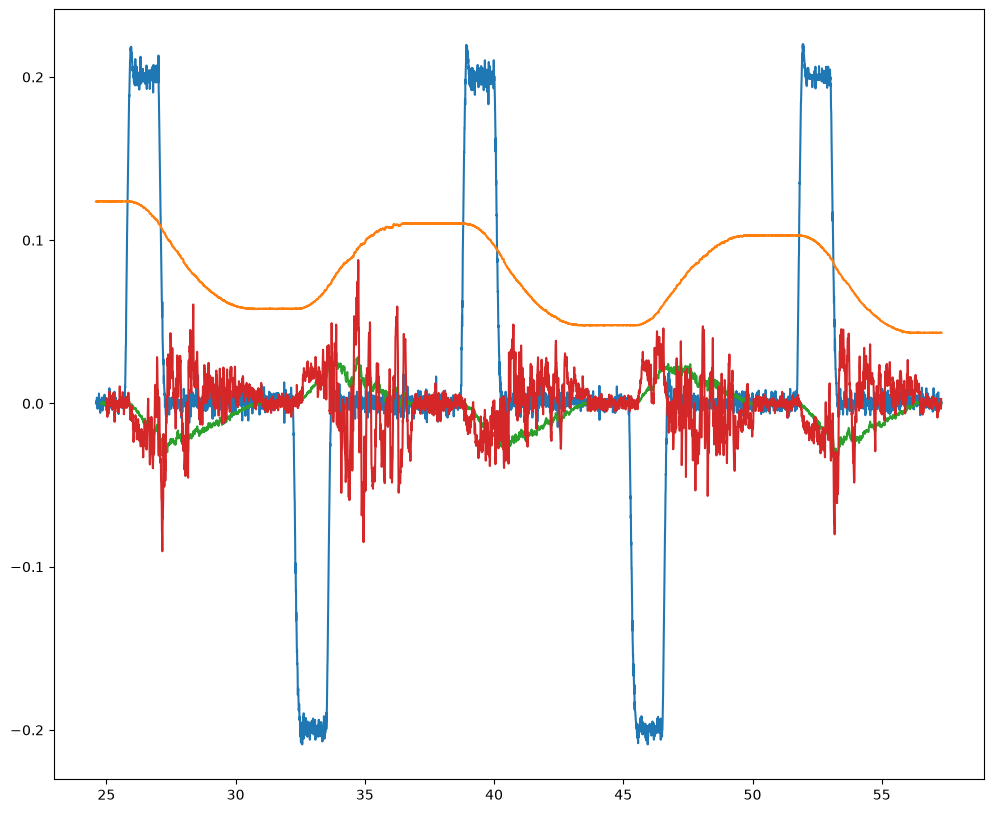

sample,time_us,theta_desired,motor_voltage,theta,ball_pos,ball_velocity,ball_acceleration
i64,i64,f64,f64,f64,f64,f64,f64
49194,24598353,0.0,-0.09669,-0.00001,0.12375,null,null
49204,24603353,0.0,-0.10112,0.00071,0.123913,null,null
49214,24608352,0.0,-0.103,0.00143,0.123837,null,null
49224,24613353,0.0,-0.103,0.00107,0.123717,null,null
49234,24618352,0.0,-0.10015,0.00071,0.123804,null,null
…,…,…,…,…,…,…,…
114575,57290415,0.0,-0.09992,0.00143,0.043317,-0.000246,-0.003295
114585,57295425,0.0,-0.08914,-0.00145,0.043263,-0.000247,0.00012
114595,57300494,0.0,-0.57633,0.00035,0.043328,0.000397,0.002764


In [151]:
# Central difference for acceleration:
# v[i] = (x[i+1] - x[i-1]) / (t[i+1] - t[i-1])
accel = (
    (df["ball_velocity"].shift(-1) - df["ball_velocity"].shift(1))
    / (df["time_us"].shift(-1) - df["time_us"].shift(1))
) * 1e6  # us -> s

df = df.with_columns([
    accel.rolling_mean(window_size=window_size).alias("ball_acceleration"),
])


plt.figure(figsize=(12, 10))
plt.plot(df["time_us"] / 1000000, df["theta"])
plt.plot(df["time_us"] / 1000000, df["ball_pos"])
plt.plot(df["time_us"] / 1000000, df["ball_velocity"])
plt.plot(df["time_us"] / 1000000, df["ball_acceleration"])
plt.show()

df

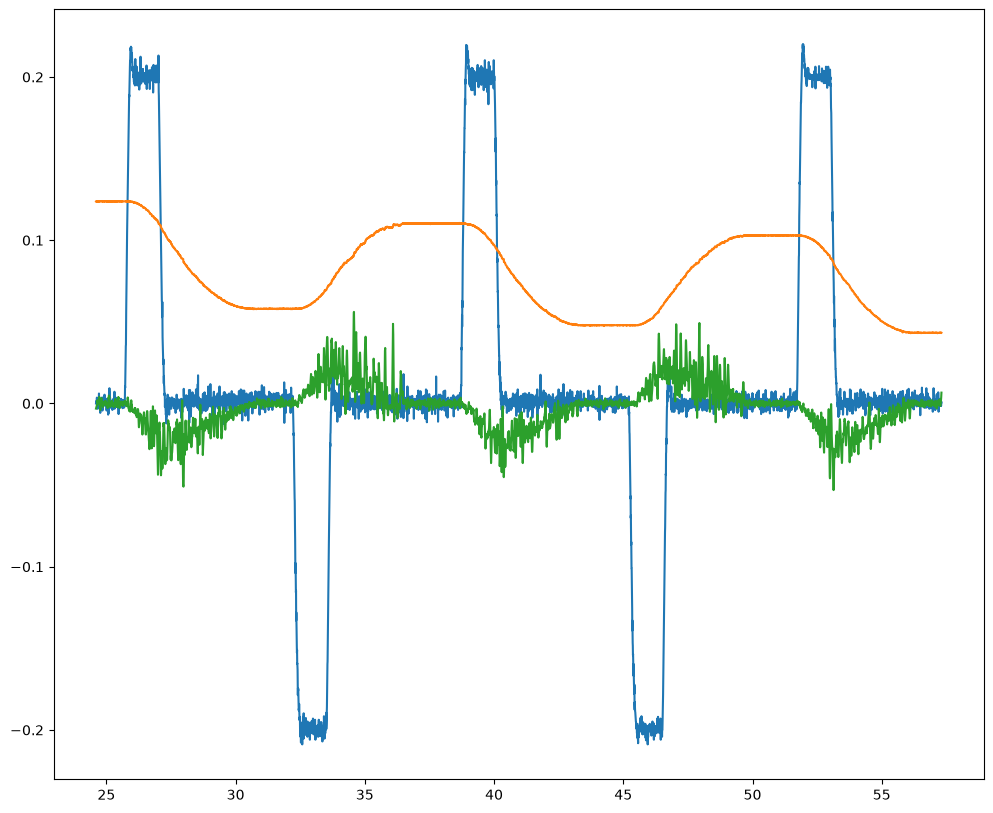

In [152]:
from scipy.signal import savgol_filter

dt = df_original["time_us"].diff().median() / 1e6

position = df_original["ball_pos"].to_numpy()

velocity = savgol_filter(position, window_length=21, polyorder=3, deriv=1, delta=dt)
acceleration = savgol_filter(position, window_length=21, polyorder=3, deriv=2, delta=dt)

df_original = df_original.with_columns([
    pl.Series("ball_velocity", velocity),
    pl.Series("ball_acceleration", acceleration),
])


plt.figure(figsize=(12, 10))
plt.plot(df_original["time_us"] / 1000000, df_original["theta"])
plt.plot(df_original["time_us"] / 1000000, df_original["ball_pos"])
plt.plot(df_original["time_us"] / 1000000, df_original["ball_velocity"])
# plt.plot(df_original["time_us"] / 1000000, df_original["ball_acceleration"])
plt.show()